# Tugas - Clustering dengan K-Means dan Hierarchical Clustering

| Nama | NRP |
|------|-----|
| Suhail Ainur Rofiq | 5054251046 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model clustering menggunakan K-Means dan Hierarchical Clustering untuk mengelompokkan posting Facebook penjual berdasarkan pola engagement-nya (like, komentar, share, dan reaksi emoji).

Dataset yang digunakan: `Live.csv` (Facebook Live Sellers in Thailand, UCI). Setiap baris adalah satu posting Facebook dari penjual fashion dan kosmetik di Thailand.

Tujuan utama dari tugas ini adalah memahami cara kerja algoritma clustering secara praktik, khususnya:
1. Penentuan jumlah cluster yang optimal (Elbow Method dan Silhouette Score) serta pengaruh transformasi log dan feature scaling pada K-Means
2. Perbedaan metode linkage dan pembacaan dendrogram pada Hierarchical Clustering
3. Perbandingan hasil K-Means dan Hierarchical Clustering

**Catatan:** Kolom `status_type` TIDAK boleh digunakan sebagai fitur clustering. Kolom ini hanya dipakai untuk membantu menafsirkan cluster pada tahap evaluasi.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   Memuat dataset, melihat struktur data, dan distribusi fitur.
2. Preprocessing
   Memproses data agar siap digunakan dalam clustering.
3. Eksperimen K-Means
   Tentukan jumlah cluster dengan Elbow Method dan Silhouette Score, lalu bangun model K-Means.
4. Eksperimen Hierarchical Clustering
   Amati dendrogram, bandingkan variasi linkage, lalu bangun model Agglomerative Clustering.
5. Evaluasi Model
   Hitung metrik evaluasi dan visualisasikan hasilnya.
6. Analisis
7. Kesimpulan dan Saran

# 1. Persiapan Dataset dan Eksplorasi Awal

### Penjelasan Langkah 1.1: Import Library
Konsep: Sebelum mengolah data dan membuat model Machine Learning, kita perlu memanggil alat bantu (library) seperti pandas untuk membaca tabel data, numpy untuk perhitungan matematika, matplotlib dan seaborn untuk membuat grafik, serta scikit-learn dan scipy yang berisi algoritma K-Means dan Hierarchical Clustering.

Apa saja yang dilakukan: Memanggil library pengolahan data (pandas, numpy), visualisasi (matplotlib, seaborn), preprocessing dan clustering (StandardScaler, KMeans, AgglomerativeClustering, PCA), metrik evaluasi, serta fungsi dendrogram dari scipy.

Tujuannya: Mempersiapkan seluruh alat bantu yang dibutuhkan agar kode pada cell berikutnya bisa membaca data, menggambar grafik, dan menjalankan algoritma clustering tanpa error.

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, scipy, dll)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

from scipy.cluster.hierarchy import linkage, dendrogram

### Penjelasan Langkah 1.2: Membaca Dataset dan Cek Kondisi Awal Data
Konsep: Tahap awal dalam pengolahan data adalah mengenal isi tabel: berapa jumlah baris dan kolomnya, apa tipe datanya, apakah ada data yang kosong (missing value), serta apakah ada baris yang ganda (duplikat).

Apa saja yang dilakukan: Membaca file Live.csv, menampilkan ukuran baris dan kolom, mengecek tipe data lewat info(), menghitung missing value tiap kolom, mengecek duplikat (termasuk duplikat jika tanpa status_id), dan menampilkan statistik ringkas lewat describe().

Tujuannya: Memastikan kondisi awal data terdeteksi sejak dini (ukuran, tipe data, kolom kosong, dan duplikat) sebelum masuk ke tahap pengolahan.

Tindak lanjut di tahap Preprocessing: Karena ditemukan 4 kolom kosong total (Column1 sampai Column4) dan 54 baris duplikat (jika tanpa status_id), di tahap Preprocessing nanti keempat kolom kosong dan baris duplikat tersebut akan dihapus.

In [2]:
# Load dataset dan tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, jumlah missing value, dan jumlah baris duplikat.
# Perhatikan apakah ada kolom yang seluruhnya kosong.
df = pd.read_csv('Live.csv')

print("Ukuran dataset (baris, kolom):", df.shape)
print("\nTipe data & info kolom:")
df.info()

print("\nJumlah missing value tiap kolom:")
print(df.isnull().sum())

print("\nJumlah baris duplikat persis:", df.duplicated().sum())
print("Jumlah duplikat jika tanpa status_id:", df.drop(columns=['status_id']).duplicated().sum())

df.describe()

Ukuran dataset (baris, kolom): (7050, 16)

Tipe data & info kolom:
<class 'pandas.DataFrame'>
RangeIndex: 7050 entries, 0 to 7049
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   status_id         7050 non-null   int64  
 1   status_type       7050 non-null   str    
 2   status_published  7050 non-null   str    
 3   num_reactions     7050 non-null   int64  
 4   num_comments      7050 non-null   int64  
 5   num_shares        7050 non-null   int64  
 6   num_likes         7050 non-null   int64  
 7   num_loves         7050 non-null   int64  
 8   num_wows          7050 non-null   int64  
 9   num_hahas         7050 non-null   int64  
 10  num_sads          7050 non-null   int64  
 11  num_angrys        7050 non-null   int64  
 12  Column1           0 non-null      float64
 13  Column2           0 non-null      float64
 14  Column3           0 non-null      float64
 15  Column4           0 non-null     

,status_id,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,Column1,Column2,Column3,Column4
count,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,0.0,0.0,0.0,0.0
mean,3525.500000,230.117163,224.356028,40.022553,215.043121,12.728652,1.289362,0.696454,0.243688,0.113191,NaN,NaN,NaN,NaN
std,2035.304031,462.625309,889.636820,131.599965,449.472357,39.972930,8.719650,3.957183,1.597156,0.726812,NaN,NaN,NaN,NaN
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
25%,1763.250000,17.000000,0.000000,0.000000,17.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
50%,3525.500000,59.500000,4.000000,0.000000,58.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
75%,5287.750000,219.000000,23.000000,4.000000,184.750000,3.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
max,7050.000000,4710.000000,20990.000000,3424.000000,4710.000000,657.000000,278.000000,157.000000,51.000000,31.000000,NaN,NaN,NaN,NaN


### Penjelasan Langkah 1.3: Melihat Distribusi dan Kemiringan (Skewness) Fitur Hitungan
Konsep: Skewness menunjukkan apakah sebaran data menumpuk di angka kecil dan hanya sedikit yang bernilai sangat besar (ekor panjang ke kanan). Boxplot dan persentase angka 0 membantu kita melihat apakah data penuh dengan angka nol dan apakah skala angkanya timpang antar kolom.

Apa saja yang dilakukan: Menghitung nilai skewness, persentase angka 0, median, dan nilai maksimum untuk 9 fitur hitungan, lalu menggambar grafik boxplot agar perbedaan skala dan outlier terlihat jelas.

Tujuannya: Mengetahui apakah ada ketimpangan skala, ekor sebaran panjang (skewness), dan dominasi angka nol yang dapat mengacaukan perhitungan jarak clustering.

Tindak lanjut di tahap Preprocessing: Karena sebaran data sangat miring ke kanan, banyak nilai 0 pada fitur emoji, dan skalanya berbeda jauh, di tahap Preprocessing nanti fitur emoji akan digabung menjadi num_emojis, lalu data akan diubah dengan transformasi log1p dan disamakan skalanya menggunakan StandardScaler.

               Skewness  Persen Nilai 0 (%)  Median    Max
num_reactions      3.74                1.72    59.5   4710
num_comments       9.03               30.06     4.0  20990
num_shares         7.10               55.48     0.0   3424
num_likes          3.92                1.79    58.0   4710
num_loves          6.00               60.00     0.0    657
num_wows          18.25               75.29     0.0    278
num_hahas         20.31               83.91     0.0    157
num_sads          17.58               91.39     0.0     51
num_angrys        19.51               94.00     0.0     31


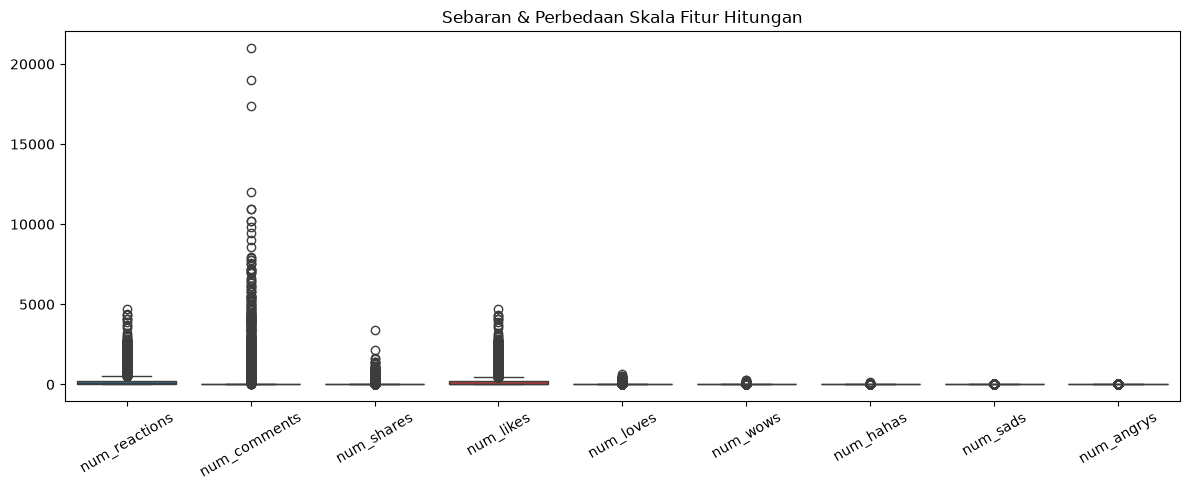

In [3]:
# Tampilkan distribusi fitur hitungan (histogram atau boxplot).
# Perhatikan skewness, proporsi nilai nol, dan perbedaan skala antar fitur (misalnya num_comments vs num_angrys), karena ini penting untuk tahap preprocessing.
fitur_hitungan = [
    'num_reactions', 'num_comments', 'num_shares', 'num_likes',
    'num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys'
]

# Cek skewness dan persentase nilai 0 untuk setiap fitur hitungan
ringkasan = pd.DataFrame({
    'Skewness': df[fitur_hitungan].skew(),
    'Persen Nilai 0 (%)': (df[fitur_hitungan] == 0).mean() * 100,
    'Median': df[fitur_hitungan].median(),
    'Max': df[fitur_hitungan].max()
})
print(ringkasan.round(2))

# Visualisasi boxplot untuk melihat outlier dan perbedaan skala
plt.figure(figsize=(12, 5))
sns.boxplot(data=df[fitur_hitungan])
plt.title('Sebaran & Perbedaan Skala Fitur Hitungan')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Penjelasan Langkah 1.4: Cek Korelasi Antar Fitur
Konsep: Korelasi (bernilai -1 sampai +1) mengukur seberapa kuat dua kolom bergerak searah. Korelasi mendekati 1.00 berarti dua kolom tersebut hampir membawa informasi yang sama persis (redundan).

Apa saja yang dilakukan: Menghitung matriks korelasi antar 9 fitur hitungan dan memvisualisasikannya dalam bentuk heatmap berwarna beserta angkanya.

Tujuannya: Mendeteksi fitur yang membawa informasi ganda (redundan) agar tidak diberi bobot berlebih saat clustering menghitung jarak antar posting.

Tindak lanjut di tahap Preprocessing: Kolom yang terbukti redundan dan berkorelasi sangat tinggi karena merupakan penjumlahan kolom lain (seperti num_reactions) akan dibuang di tahap Preprocessing agar tidak dihitung ganda dalam rumus jarak.

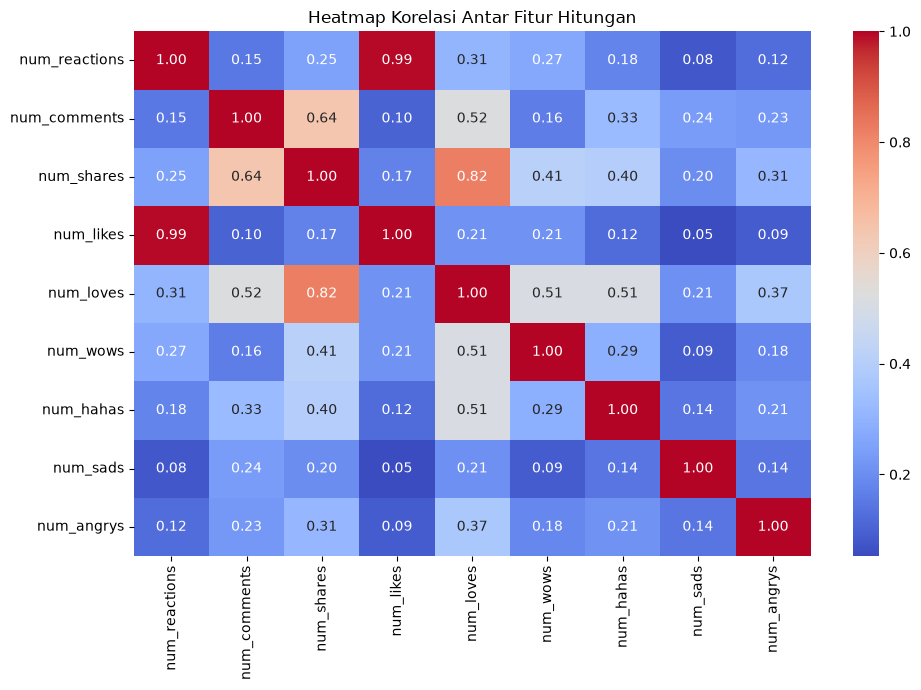

In [4]:
# Tampilkan heatmap korelasi antar fitur hitungan.
# Perhatikan fitur-fitur yang berkorelasi sangat tinggi atau saling berkaitan secara definisi (redundan), karena memengaruhi perhitungan jarak pada clustering.
plt.figure(figsize=(10, 7))
korelasi = df[fitur_hitungan].corr()
sns.heatmap(korelasi, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Heatmap Korelasi Antar Fitur Hitungan')
plt.tight_layout()
plt.show()

### Penjelasan Langkah 1.5: Melihat Perubahan Pola Waktu (Tahun) dan Reaksi Emoji
Konsep: Kolom tanggal (status_published) awalnya hanya dibaca komputer sebagai teks biasa. Dengan mengubahnya ke format datetime, kita bisa mengambil tahun posting-nya dan mengecek sejak tahun berapa reaksi emoji Facebook mulai muncul.

Apa saja yang dilakukan: Mengubah status_published menjadi format datetime, mengambil tahunnya, menghitung jumlah posting serta persentase posting yang memiliki reaksi emoji per tahun, lalu membuat grafik batang jumlah posting tiap tahun.

Tujuannya: Memahami sejak tahun berapa fitur reaksi emoji aktif di Facebook agar kita tidak salah mengira nilai 0 di tahun lama sebagai kesalahan data.

Tindak lanjut di tahap Preprocessing: Karena reaksi emoji baru muncul di tahun 2016 dan sebelumnya bernilai 0 semua, di tahap Preprocessing nanti kelima kolom emoji tersebut tidak dipakai sendiri-sendiri melainkan digabung menjadi satu fitur num_emojis, sedangkan status_published dipisahkan karena tidak dipakai untuk clustering.

       jumlah_posting  proporsi_emoji (%)
tahun                                    
2012              589                0.00
2013              500                0.00
2014              233                0.00
2015              337                0.00
2016              588               68.03
2017             2253               54.19
2018             2550               57.76


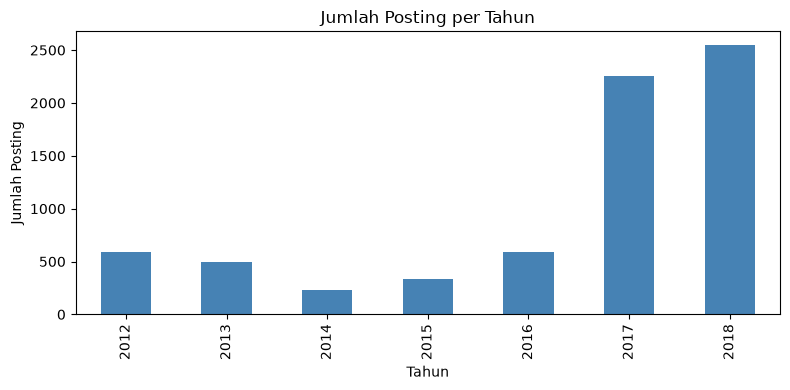

In [5]:
# Ubah kolom status_published menjadi datetime.
# Tampilkan jumlah posting dan proporsi posting yang memiliki reaksi emoji pada setiap tahun.
# Amati apakah ada perubahan pola dari tahun ke tahun.
df['status_published'] = pd.to_datetime(df['status_published'])
df['tahun'] = df['status_published'].dt.year

# Cek apakah posting memiliki minimal 1 reaksi emoji (selain like)
emoji_cols = ['num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']
df['punya_emoji'] = (df[emoji_cols].sum(axis=1) > 0).astype(int)

pola_tahun = df.groupby('tahun').agg(
    jumlah_posting=('status_id', 'count'),
    proporsi_emoji=('punya_emoji', 'mean')
)
pola_tahun['proporsi_emoji (%)'] = (pola_tahun['proporsi_emoji'] * 100).round(2)
print(pola_tahun[['jumlah_posting', 'proporsi_emoji (%)']])

# Grafik jumlah posting per tahun
plt.figure(figsize=(8, 4))
pola_tahun['jumlah_posting'].plot(kind='bar', color='steelblue')
plt.title('Jumlah Posting per Tahun')
plt.xlabel('Tahun')
plt.ylabel('Jumlah Posting')
plt.tight_layout()
plt.show()

### Penjelasan Langkah 1.6: Eksplorasi Tipe Posting (status_type)
Konsep: Setiap posting di Facebook punya jenis media berbeda (video, photo, status, link). Kita memakai median (nilai tengah) untuk membandingkan engagement tiap jenis posting karena median tidak mudah tertipu oleh satu atau dua posting viral yang nilainya sangat tinggi.

Apa saja yang dilakukan: Membuat grafik batang jumlah posting untuk masing-masing status_type dan menghitung nilai median num_likes, num_comments, serta num_shares per status_type.

Tujuannya: Mengenal perbedaan pola engagement alami tiap jenis posting (video, photo, status, link) sebagai bekal untuk menamai cluster di tahap akhir.

Tindak lanjut di tahap Preprocessing: Sesuai aturan tugas, di tahap Preprocessing nanti kolom status_type akan dipisahkan dan tidak dimasukkan ke fitur pelatihan model clustering, melainkan hanya disimpan untuk membantu menafsirkan arti tiap cluster pada tahap evaluasi.

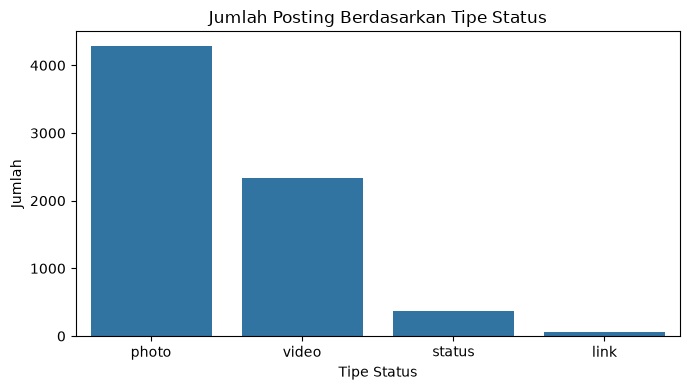

Median engagement per status_type:
             num_likes  num_comments  num_shares
status_type                                     
link              48.0           1.0         0.0
photo             34.0           2.0         0.0
status           117.0          10.0         0.0
video            117.0          39.0        12.0


In [6]:
# Tampilkan distribusi status_type dalam bentuk bar plot.
# Bandingkan median num_likes, num_comments, dan num_shares untuk setiap status_type.
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='status_type', order=df['status_type'].value_counts().index)
plt.title('Jumlah Posting Berdasarkan Tipe Status')
plt.xlabel('Tipe Status')
plt.ylabel('Jumlah')
plt.tight_layout()
plt.show()

# Bandingkan median likes, comments, dan shares tiap status_type
median_per_type = df.groupby('status_type')[['num_likes', 'num_comments', 'num_shares']].median()
print("Median engagement per status_type:")
print(median_per_type)

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

### Penjelasan Langkah 1.7: EDA Tambahan (Cek Hubungan Penjumlahan num_reactions)
Konsep: Kita mengecek secara matematis apakah num_reactions benar-benar sama persis dengan penjumlahan num_likes ditambah semua reaksi emoji (num_loves sampai num_angrys).

Apa saja yang dilakukan: Menjumlahkan num_likes dengan 5 kolom reaksi emoji, lalu menghitung selisihnya terhadap num_reactions untuk membuktikan apakah kolom tersebut redundan.

Tujuannya: Membuktikan secara pasti lewat perhitungan angka bahwa kolom num_reactions memang hasil penjumlahan kolom lain sehingga aman untuk dibuang.

Tindak lanjut di tahap Preprocessing: Karena terbukti num_reactions adalah hasil penjumlahan dari num_likes dan reaksi emoji, maka di tahap Preprocessing nanti kolom num_reactions dipastikan akan dibuang.

In [7]:
# Cek apakah num_reactions adalah jumlah dari num_likes + semua reaksi emoji
total_komponen = df['num_likes'] + df[emoji_cols].sum(axis=1)
selisih = (df['num_reactions'] - total_komponen).abs()

print("Jumlah baris di mana num_reactions == jumlah like + emoji:", (selisih == 0).sum(), "dari", len(df))
print("Selisih maksimum:", selisih.max())

Jumlah baris di mana num_reactions == jumlah like + emoji: 7041 dari 7050
Selisih maksimum: 4


# 2. Preprocessing

### Penjelasan Langkah 2.1: Pembersihan Data (Kolom Kosong, Duplikat, dan Outlier)
Konsep: Data mentah sering memiliki kolom sampah yang seluruhnya kosong atau baris yang tercatat ganda. Di dataset ini, status_id selalu unik untuk tiap baris, jadi untuk mencari posting yang sebenarnya kembar, kita harus mengecek duplikat pada kolom-kolom selain status_id.

Apa saja yang dilakukan: Membuang 4 kolom kosong (Column1 sampai Column4) dan kolom bantu EDA, menghapus 54 baris duplikat (dicek tanpa status_id), lalu memeriksa kembali sisa missing value.

Tujuannya: Membuat dataset bersih dari kolom sampah dan baris ganda agar titik pusat cluster (centroid) tidak bergeser ke arah data yang tercatat dua kali.

In [8]:
# Hapus kolom yang seluruhnya kosong.
# Periksa dan tangani baris duplikat (ingat bahwa status_id selalu unik untuk tiap baris).
# Periksa juga missing value dan outlier ekstrem, lalu tentukan penanganannya.

# 1. Hapus 4 kolom kosong dan kolom bantu EDA sebelumnya
df_clean = df.drop(columns=['Column1', 'Column2', 'Column3', 'Column4', 'tahun', 'punya_emoji'])

# 2. Hapus baris duplikat berdasarkan semua kolom selain status_id
kolom_cek = [col for col in df_clean.columns if col != 'status_id']
jumlah_awal = len(df_clean)
df_clean = df_clean.drop_duplicates(subset=kolom_cek).reset_index(drop=True)

print(f"Baris sebelum hapus duplikat : {jumlah_awal}")
print(f"Baris sesudah hapus duplikat : {len(df_clean)} (terhapus {jumlah_awal - len(df_clean)} baris)")
print("Sisa missing values:", df_clean.isnull().sum().sum())

# Catatan outlier ekstrem: nilai ekstrem (posting sangat viral) tetap dipertahankan karena merupakan perilaku asli penjual,
# dan akan ditangani pada langkah transformasi log1p agar jaraknya tidak mendominasi cluster.

Baris sebelum hapus duplikat : 7050
Baris sesudah hapus duplikat : 6996 (terhapus 54 baris)
Sisa missing values: 0


### Penjelasan Langkah 2.2: Pemisahan Label Evaluasi dan Pemilihan Fitur Clustering
Konsep: Clustering adalah *Unsupervised Learning*, artinya algoritma mencari kelompok sendiri hanya dari angka engagement tanpa tahu jenis posting-nya (status_type). Untuk fitur emoji yang banyak bernilai nol (num_loves, num_wows, num_hahas, num_sads, num_angrys), kita gabungkan menjadi satu kolom num_emojis agar informasinya tetap terpakai tanpa menambah banyak kolom yang hampir kosong.

Apa saja yang dilakukan: Menyimpan status_type dan status_published ke variabel meta_df (khusus evaluasi), menggabungkan 5 kolom reaksi emoji menjadi satu kolom baru num_emojis, lalu memilih 4 fitur angka utama (num_likes, num_comments, num_shares, num_emojis) ke X_raw_df.

Tujuannya: Memastikan algoritma hanya belajar dari fitur angka engagement yang bersih dan tidak bocor menggunakan label evaluasi status_type.

In [9]:
# Pisahkan status_type dan status_published (untuk interpretasi cluster pada tahap evaluasi) dari fitur yang akan dipakai untuk clustering.
# Hapus kolom yang tidak relevan untuk clustering (misalnya status_id).
# Periksa apakah ada fitur yang redundan (misalnya fitur yang merupakan penjumlahan fitur lain) atau yang sebagian besar bernilai nol.
# Pilih fitur yang akan dipakai untuk clustering. Pertimbangkan untuk menggabungkan fitur yang sparse.
# Catatan: K-Means dan Hierarchical Clustering berbasis jarak, sehingga semua fitur harus berupa angka.

# Simpan status_type dan status_published untuk evaluasi
meta_df = df_clean[['status_type', 'status_published']].copy()

# Gabungkan 5 kolom reaksi emoji yang sparse menjadi satu fitur total emoji
df_clean['num_emojis'] = df_clean[['num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']].sum(axis=1)

# Pilih fitur angka final yang tidak redundan untuk clustering
selected_features = ['num_likes', 'num_comments', 'num_shares', 'num_emojis']
X_raw_df = df_clean[selected_features].copy()

print("Fitur terpilih untuk clustering:", selected_features)
X_raw_df.head()

Fitur terpilih untuk clustering: ['num_likes', 'num_comments', 'num_shares', 'num_emojis']


,num_likes,num_comments,num_shares,num_emojis
0,432,512,262,97
1,150,0,0,0
2,204,236,57,23
3,111,0,0,0
4,204,0,0,9


Fitur yang dipilih untuk clustering:
1. num_likes: Mengukur tingkat kesukaan umum terhadap posting.
2. num_comments: Mengukur seberapa aktif interaksi tanya jawab pembeli (sangat tinggi saat live video jualan).
3. num_shares: Mengukur seberapa sering posting dibagikan ke pengguna lain.
4. num_emojis: Gabungan dari 5 kolom reaksi emoji yang sebagian besar bernilai nol (num_loves, num_wows, num_hahas, num_sads, num_angrys), digabung agar informasi reaksi emosional tetap terwakili tanpa membuat terlalu banyak dimensi kosong (*sparse*).

Fitur yang dibuang:
1. status_id: Hanya berupa ID unik posting, tidak punya makna pola engagement.
2. status_type dan status_published: Dipisahkan dan tidak dipakai untuk clustering, hanya untuk interpretasi pada tahap evaluasi.
3. num_reactions: Dibuang karena terbukti redundan (merupakan hasil penjumlahan persis dari num_likes ditambah semua reaksi emoji).

### Penjelasan Langkah 2.3: Transformasi Log (log1p)
Konsep: Fungsi np.log1p(x) menghitung log(1 + x). Fungsi ini merapatkan angka-angka raksasa (seperti 4.000 komentar menjadi sekitar 8.3) sambil menjaga angka 0 tetap menjadi 0 (karena log(1 + 0) = 0).

Apa saja yang dilakukan: Menerapkan np.log1p() pada 4 fitur terpilih dan menggambar histogram perbandingan distribusi data sebelum dan sesudah transformasi log.

Tujuannya: Memperkecil jarak angka-angka ekstrem (posting viral) agar ribuan posting biasa tidak tertindih dan menumpuk menjadi satu kelompok saja.

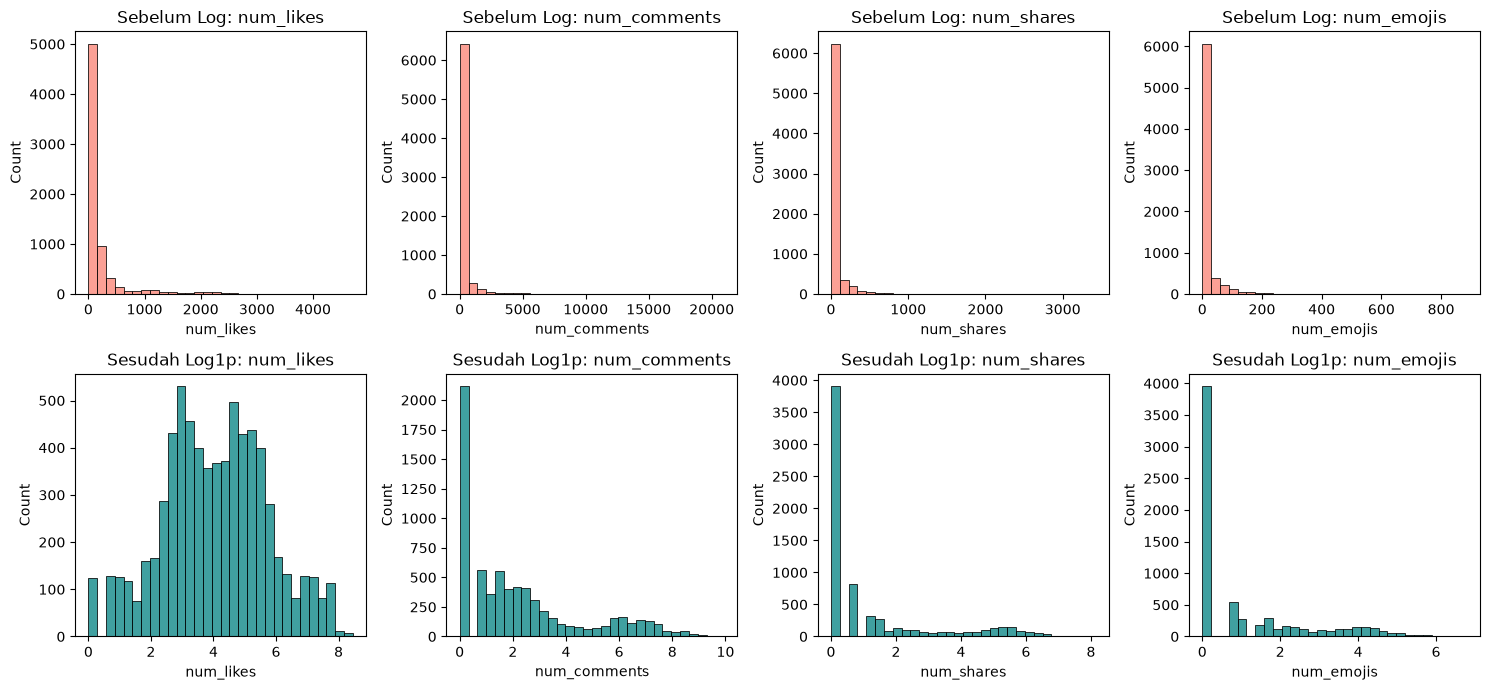

In [10]:
# Fitur hitungan pada dataset ini sangat miring (skewed). Terapkan transformasi log1p pada fitur yang dipilih.
# Tampilkan distribusi fitur sebelum dan sesudah transformasi untuk melihat perbedaannya.
X_log_df = np.log1p(X_raw_df)

fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for i, col in enumerate(selected_features):
    sns.histplot(X_raw_df[col], bins=30, ax=axes[0, i], color='salmon')
    axes[0, i].set_title(f'Sebelum Log: {col}')
    
    sns.histplot(X_log_df[col], bins=30, ax=axes[1, i], color='teal')
    axes[1, i].set_title(f'Sesudah Log1p: {col}')

plt.tight_layout()
plt.show()

### Penjelasan Langkah 2.4: Feature Scaling (StandardScaler)
Konsep: StandardScaler menyamakan skala seluruh kolom sehingga setiap kolom memiliki rata-rata 0 dan standar deviasi 1.

Apa saja yang dilakukan: Menyiapkan 3 versi data untuk eksperimen: X_raw (data mentah), X_raw_scaled (data mentah yang di-scaling dengan StandardScaler), dan X_log_scaled (data hasil log1p yang di-scaling dengan StandardScaler).

Tujuannya: Membuat semua fitur memiliki bobot yang setara dalam perhitungan jarak Euclidean, sekaligus menyiapkan data pembanding untuk eksperimen 3.1.

In [11]:
# Lakukan feature scaling (misalnya StandardScaler) pada fitur hasil transformasi log dan simpan hasilnya (X_log_scaled).
# Simpan juga versi lain untuk keperluan perbandingan pada bagian 3.1:
# - X_raw: fitur mentah tanpa transformasi dan tanpa scaling
# - X_raw_scaled: fitur mentah dengan scaling saja
scaler_raw = StandardScaler()
scaler_log = StandardScaler()

X_raw = X_raw_df.values
X_raw_scaled = scaler_raw.fit_transform(X_raw_df)
X_log_scaled = scaler_log.fit_transform(X_log_df)

print("Bentuk X_raw        :", X_raw.shape)
print("Bentuk X_raw_scaled :", X_raw_scaled.shape)
print("Bentuk X_log_scaled :", X_log_scaled.shape)

Bentuk X_raw        : (6996, 4)
Bentuk X_raw_scaled : (6996, 4)
Bentuk X_log_scaled : (6996, 4)


# 3. Eksperimen K-Means

## 3.1 Pengaruh Transformasi Log dan Feature Scaling pada K-Means

K-Means mengelompokkan data dengan meminimalkan jarak antara titik dan centroid cluster. Pada bagian ini kalian akan mengamati bagaimana transformasi log dan scaling memengaruhi hasil clustering.

### Penjelasan Langkah 3.1.1: Melatih K-Means pada 3 Versi Data
Konsep: Kita melatih 3 model K-Means dengan jumlah cluster yang sama (k = 3) dan pengaturan awal yang sama (random_state=42, n_init=10) pada tiga kondisi data: mentah (X_raw), hanya di-scaling (X_raw_scaled), serta log + scaling (X_log_scaled).

Apa saja yang dilakukan: Menjalankan KMeans(n_clusters=3) pada X_raw, X_raw_scaled, dan X_log_scaled secara terpisah untuk dibandingkan hasilnya.

Tujuannya: Menguji dan membandingkan secara langsung bagaimana hasil pengelompokan berubah ketika data dibiarkan mentah, hanya di-scaling, atau di-log lalu di-scaling.

In [12]:
# Latih K-Means dengan jumlah cluster yang sama (misalnya k=3) pada tiga versi data:
# (1) X_raw (mentah tanpa scaling), (2) X_raw_scaled (mentah dengan scaling), dan (3) X_log_scaled (log dan scaling).
# Gunakan random_state dan n_init yang sama agar perbandingan adil.
km_raw = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_raw)
km_raw_scaled = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_raw_scaled)
km_log_scaled = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_log_scaled)

print("Ketiga model K-Means (k=3) berhasil dilatih.")

Ketiga model K-Means (k=3) berhasil dilatih.


### Penjelasan Langkah 3.1.2: Membandingkan Keseimbangan Cluster dan Silhouette Score
Konsep: Silhouette Score mengukur apakah titik-titik di dalam satu cluster berkumpul rapat dan terpisah jauh dari cluster lain (nilai terbaik mendekati 1). Kita menghitung Silhouette Score ketiganya di ruang yang sama (X_log_scaled) agar perbandingannya adil.

Apa saja yang dilakukan: Menampilkan varians tiap fitur pada X_raw, menghitung jumlah anggota per cluster serta Silhouette Score (di ruang X_log_scaled) untuk ketiga versi data, lalu menyajikannya dalam tabel.

Tujuannya: Membuktikan lewat angka Silhouette dan sebaran jumlah anggota cluster versi data mana yang membagi kelompok paling seimbang dan rapi.

In [13]:
# Bandingkan ketiga hasil tersebut: jumlah anggota tiap cluster dan Silhouette Score.
# Hitung Silhouette ketiganya pada ruang yang sama (misalnya X_log_scaled) agar perbandingannya adil.
# Amati fitur mana yang mendominasi varians pada data tanpa scaling, dan apakah ada cluster yang sangat kecil atau sangat besar.
hasil_31 = []
versi_data = [
    ('1. X_raw (Tanpa Log & Scaling)', km_raw.labels_),
    ('2. X_raw_scaled (Scaling Saja)', km_raw_scaled.labels_),
    ('3. X_log_scaled (Log + Scaling)', km_log_scaled.labels_)
]

for nama, labels in versi_data:
    counts = pd.Series(labels).value_counts().sort_index().to_dict()
    sil = silhouette_score(X_log_scaled, labels)
    hasil_31.append({
        'Versi Data': nama,
        'Silhouette (di ruang X_log_scaled)': round(sil, 4),
        'Jumlah Anggota per Cluster': counts
    })

print("Varians tiap fitur pada X_raw (tanpa scaling):")
print(X_raw_df.var().round(2))
print("\nPerbandingan hasil clustering:")
pd.DataFrame(hasil_31)

Varians tiap fitur pada X_raw (tanpa scaling):
num_likes       193268.44
num_comments    797310.07
num_shares       17443.17
num_emojis        2299.57
dtype: float64

Perbandingan hasil clustering:


,Versi Data,Silhouette (di ruang X_log_scaled),Jumlah Anggota per Cluster
0,1. X_raw (Tanpa Log & Scaling),0.2731,"{0: 6392, 1: 137, 2: 467}"
1,2. X_raw_scaled (Scaling Saja),0.2533,"{0: 373, 1: 6277, 2: 346}"
2,3. X_log_scaled (Log + Scaling),0.4638,"{0: 1131, 1: 2258, 2: 3607}"


## 3.2 Menentukan Jumlah Cluster dengan Elbow Method

Elbow Method memplot nilai inertia (Within-Cluster Sum of Squares) terhadap jumlah cluster k. Titik "siku" pada grafik menunjukkan nilai k setelah mana penambahan cluster tidak lagi memberikan penurunan inertia yang berarti.

### Penjelasan Langkah 3.2.1: Menghitung Nilai Inertia untuk k = 2 sampai 10
Konsep: *Inertia* adalah total jarak kuadrat dari setiap titik data ke titik pusat cluster-nya. Semakin banyak cluster (k makin besar), nilai inertia pasti makin kecil karena cluster makin sempit.

Apa saja yang dilakukan: Melatih K-Means secara berulang untuk k = 2 hingga 10 pada X_log_scaled dan menyimpan nilai inertia masing-masing ke dalam list.

Tujuannya: Mengumpulkan nilai inertia dari berbagai jumlah cluster (k) agar bisa diamati titik di mana penambahan cluster tidak lagi memberi perbaikan berarti.

In [14]:
# Latih K-Means pada X_log_scaled untuk rentang k tertentu (misalnya k = 2 sampai 10).
# Simpan nilai inertia untuk setiap k.
k_range = range(2, 11)
inertias = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_log_scaled)
    inertias.append(km.inertia_)

for k, iner in zip(k_range, inertias):
    print(f"k = {k:2d} -> Inertia = {iner:.2f}")

k =  2 -> Inertia = 11586.90
k =  3 -> Inertia = 6779.84
k =  4 -> Inertia = 5678.25
k =  5 -> Inertia = 4739.96
k =  6 -> Inertia = 4220.28
k =  7 -> Inertia = 3772.10
k =  8 -> Inertia = 3418.57
k =  9 -> Inertia = 3116.43
k = 10 -> Inertia = 2899.05


### Penjelasan Langkah 3.2.2: Membuat Grafik Elbow Method
Konsep: Jika grafik k vs inertia digambar, bentuknya akan menyerupai lengan manusia yang menekuk. Titik tekukan siku (*elbow*) adalah kandidat jumlah cluster yang paling pas: tidak terlalu sedikit, dan juga tidak terlalu banyak sampai memecah kelompok secara berlebihan.

Apa saja yang dilakukan: Menggambar grafik garis antara nilai k (2 sampai 10) dengan nilai inertia-nya untuk mencari titik tekukan siku (*elbow*).

Tujuannya: Menemukan jumlah cluster (k) yang paling pas secara visual lewat titik tekukan siku (elbow) pada grafik.

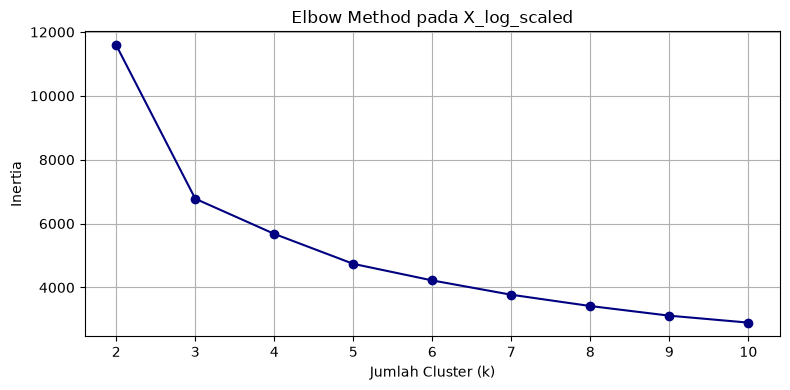

In [15]:
# Plot grafik Elbow (k vs inertia).
# Amati pada nilai k berapa terbentuk "siku".
# (Opsional) Gunakan library kneed (KneeLocator) untuk mendeteksi elbow secara otomatis, lalu bandingkan dengan pengamatan kalian.
plt.figure(figsize=(8, 4))
plt.plot(k_range, inertias, marker='o', linestyle='-', color='navy')
plt.title('Elbow Method pada X_log_scaled')
plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('Inertia')
plt.xticks(k_range)
plt.grid(True)
plt.tight_layout()
plt.show()

## 3.3 Menentukan Jumlah Cluster dengan Silhouette Score

Silhouette Score mengukur seberapa mirip sebuah titik dengan clusternya sendiri dibandingkan dengan cluster lain. Nilainya berkisar dari -1 sampai 1, semakin tinggi semakin baik.

### Penjelasan Langkah 3.3.1: Menghitung Silhouette Score untuk k = 2 sampai 10
Konsep: Berbeda dengan Inertia yang selalu turun jika k ditambah, Silhouette Score bisa naik dan turun. Nilai tinggi berarti tiap anggota sudah sangat cocok berada di clusternya dan terpisah rapi dari cluster tetangga.

Apa saja yang dilakukan: Melatih K-Means dan menghitung nilai silhouette_score pada X_log_scaled untuk setiap nilai k dari 2 sampai 10.

Tujuannya: Mendapatkan ukuran kualitas pemisahan cluster secara objektif untuk memvalidasi kandidat jumlah cluster dari Elbow Method.

In [16]:
# Hitung Silhouette Score untuk setiap nilai k pada rentang yang sama dengan Elbow Method.
# Simpan hasilnya dalam list atau dictionary agar mudah diplot.
sil_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_log_scaled)
    score = silhouette_score(X_log_scaled, labels)
    sil_scores.append(score)

for k, sc in zip(k_range, sil_scores):
    print(f"k = {k:2d} -> Silhouette Score = {sc:.4f}")

k =  2 -> Silhouette Score = 0.5899
k =  3 -> Silhouette Score = 0.4638
k =  4 -> Silhouette Score = 0.3372
k =  5 -> Silhouette Score = 0.3586
k =  6 -> Silhouette Score = 0.3469
k =  7 -> Silhouette Score = 0.3367
k =  8 -> Silhouette Score = 0.3154
k =  9 -> Silhouette Score = 0.3293
k = 10 -> Silhouette Score = 0.3160


### Penjelasan Langkah 3.3.2: Plot Grafik Silhouette Score
Konsep: Dengan menggambar grafik garis Silhouette Score terhadap k, kita bisa langsung melihat puncak nilai tertinggi dan membandingkannya dengan titik siku dari Elbow Method sebelumnya.

Apa saja yang dilakukan: Membuat grafik garis antara nilai k dan Silhouette Score-nya agar titik tertinggi mudah diamati.

Tujuannya: Melihat puncak skor Silhouette pada grafik agar kita bisa menentukan jumlah cluster terbaik sebelum melatih model final.

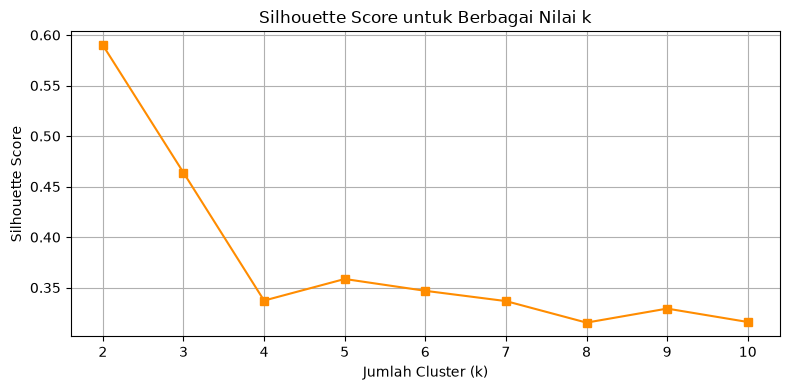

In [17]:
# Plot grafik Silhouette Score terhadap k.
# Tentukan nilai k terbaik dengan mempertimbangkan hasil Elbow Method dan Silhouette Score, lalu jelaskan alasannya pada cell markdown di bawah.
plt.figure(figsize=(8, 4))
plt.plot(k_range, sil_scores, marker='s', linestyle='-', color='darkorange')
plt.title('Silhouette Score untuk Berbagai Nilai k')
plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('Silhouette Score')
plt.xticks(k_range)
plt.grid(True)
plt.tight_layout()
plt.show()

Pilihan k untuk K-Means:
Berdasarkan hasil Elbow Method dan Silhouette Score:
1. Pada Elbow Method, penurunan inertia paling tajam terjadi dari k = 2 (11.586,9) menuju k = 3 (6.779,8), lalu setelah k = 3 penurunannya mulai melandai. Jadi titik siku (*elbow*) terlihat jelas di k = 3.
2. Pada Silhouette Score, nilai tertinggi memang ada di k = 2 (0.5899), namun pada k = 3 nilainya masih tinggi (0.4638) sebelum akhirnya anjlok ke 0.3372 pada k = 4.

Oleh karena itu, dipilih k = 3 karena merupakan titik temu terbaik antara Elbow Method dan Silhouette Score, serta mampu membagi pola engagement menjadi 3 segmen yang lebih informatif (rendah, sedang, tinggi/viral) dibandingkan hanya 2 segmen.

## 3.4 Model K-Means Final

### Penjelasan Langkah 3.4.1: Melatih Model K-Means Final
Konsep: Setelah menemukan k optimal, kita melatih model K-Means final pada X_log_scaled dan menyimpan nomor label clusternya (0, 1, 2, ...) untuk setiap posting.

Apa saja yang dilakukan: Melatih KMeans final dengan k = 3 pada X_log_scaled, menyimpan label prediksinya ke labels_kmeans, dan mencetak jumlah anggota tiap cluster.

Tujuannya: Menghasilkan pengelompokan final K-Means dengan jumlah cluster optimal yang siap dianalisis dan dibandingkan dengan metode lain.

In [18]:
# Latih model K-Means final dengan nilai k terbaik yang kalian pilih pada X_log_scaled.
# Simpan label cluster hasil prediksi untuk keperluan evaluasi.
k_optimal = 3
kmeans_final = KMeans(n_clusters=k_optimal, random_state=42, n_init=10)
labels_kmeans = kmeans_final.fit_predict(X_log_scaled)

print(f"Jumlah cluster dipilih (k): {k_optimal}")
print("Jumlah anggota tiap cluster (K-Means):")
print(pd.Series(labels_kmeans).value_counts().sort_index())

Jumlah cluster dipilih (k): 3
Jumlah anggota tiap cluster (K-Means):
0    1131
1    2258
2    3607
Name: count, dtype: int64


### Penjelasan Langkah 3.4.2: Membaca Profil Cluster pada Data Asli
Konsep: Data X_log_scaled sudah berubah skalanya sehingga angkanya sulit dibayangkan oleh manusia (misal num_likes = -0.45). Untuk memahami ciri asli tiap kelompok, kita tempelkan label clusternya ke data asli (X_raw_df) lalu hitung median dan rata-ratanya.

Apa saja yang dilakukan: Menggabungkan labels_kmeans dengan X_raw_df, lalu menghitung jumlah anggota, nilai median, dan nilai rata-rata setiap fitur per cluster.

Tujuannya: Menerjemahkan kelompok cluster yang tadinya hanya berupa angka label (0, 1, 2) menjadi profil engagement nyata yang mudah dibaca manusia.

In [19]:
# Buat profil setiap cluster pada data ASLI (sebelum transformasi log dan scaling): tampilkan median (dan rata-rata) tiap fitur per cluster beserta jumlah anggotanya.
# Gunakan median karena distribusi fitur sangat miring.
# Ini membantu menginterpretasikan karakteristik tiap cluster.
profil_km = X_raw_df.copy()
profil_km['Cluster'] = labels_kmeans

print("=== Jumlah Anggota & Median Tiap Fitur per Cluster (K-Means) ===")
summary_km_median = profil_km.groupby('Cluster').agg(['count', 'median'])
# Tampilkan jumlah anggota dan median secara ringkas
ringkas_km = profil_km.groupby('Cluster')[selected_features].median()
ringkas_km.insert(0, 'Jumlah Anggota', profil_km['Cluster'].value_counts().sort_index())
print(ringkas_km)

print("\n=== Rata-Rata (Mean) Tiap Fitur per Cluster (K-Means) ===")
print(profil_km.groupby('Cluster')[selected_features].mean().round(2))

=== Jumlah Anggota & Median Tiap Fitur per Cluster (K-Means) ===
         Jumlah Anggota  num_likes  num_comments  num_shares  num_emojis
Cluster                                                                 
0                  1131      170.0         722.0       178.0        57.0
1                  2258      206.0          11.0         1.0         2.0
2                  3607       18.0           0.0         0.0         0.0

=== Rata-Rata (Mean) Tiap Fitur per Cluster (K-Means) ===
         num_likes  num_comments  num_shares  num_emojis
Cluster                                                 
0           304.50       1335.37      238.04       83.25
1           462.73         26.89        4.69        4.57
2            22.23          2.11        0.55        0.23


# 4. Eksperimen Hierarchical Clustering

## 4.1 Dendrogram

Hierarchical Clustering (Agglomerative) memulai dengan setiap titik sebagai cluster tersendiri, lalu menggabungkan dua cluster terdekat secara berulang hingga tersisa satu cluster. Dendrogram memvisualisasikan proses penggabungan tersebut.

### Penjelasan Langkah 4.1.1: Menghitung Linkage Matrix dengan Metode Ward
Konsep: Berbeda dengan K-Means yang langsung melempar k titik pusat, Hierarchical Clustering bekerja bertahap dari bawah ke atas: setiap posting awalnya dianggap sebagai 1 cluster sendiri, lalu dua cluster paling mirip digabung terus-menerus hingga semua menyatu. Metode ward menggabungkan dua cluster yang paling sedikit menaikkan varians total di dalam cluster.

Apa saja yang dilakukan: Menghitung linkage_matrix pada X_log_scaled menggunakan linkage(..., method='ward') dan mencetak ukuran matriksnya.

Tujuannya: Merekam seluruh urutan penggabungan data dari bawah ke atas sehingga struktur hierarki kelompoknya bisa digambar menjadi dendrogram.

In [20]:
# Hitung linkage matrix (scipy.cluster.hierarchy.linkage) dengan metode ward pada X_log_scaled.
# Dataset berisi sekitar 7.000 baris sehingga proses ini masih ringan dan tidak perlu dilakukan sampling.
linkage_matrix = linkage(X_log_scaled, method='ward')
print("Linkage matrix selesai dihitung. Bentuk:", linkage_matrix.shape)

Linkage matrix selesai dihitung. Bentuk: (6995, 4)


### Penjelasan Langkah 4.1.2: Menampilkan Grafik Dendrogram
Konsep: Dendrogram adalah diagram pohon silsilah penggabungan data. Sumbu vertikal menunjukkan seberapa jauh jarak dua kelompok saat digabungkan. Karena ada sekitar 7.000 posting, kita memakai truncate_mode='lastp' dan p=30 untuk hanya menampilkan 30 cabang penggabungan teratas agar diagram tidak penuh sesak.

Apa saja yang dilakukan: Menggambar grafik dendrogram dari linkage_matrix dengan pembatasan 30 cabang terakhir agar mudah dibaca.

Tujuannya: Memudahkan pembacaan struktur pohon penggabungan dan melihat batas ketinggian pemotongan cluster yang paling masuk akal.

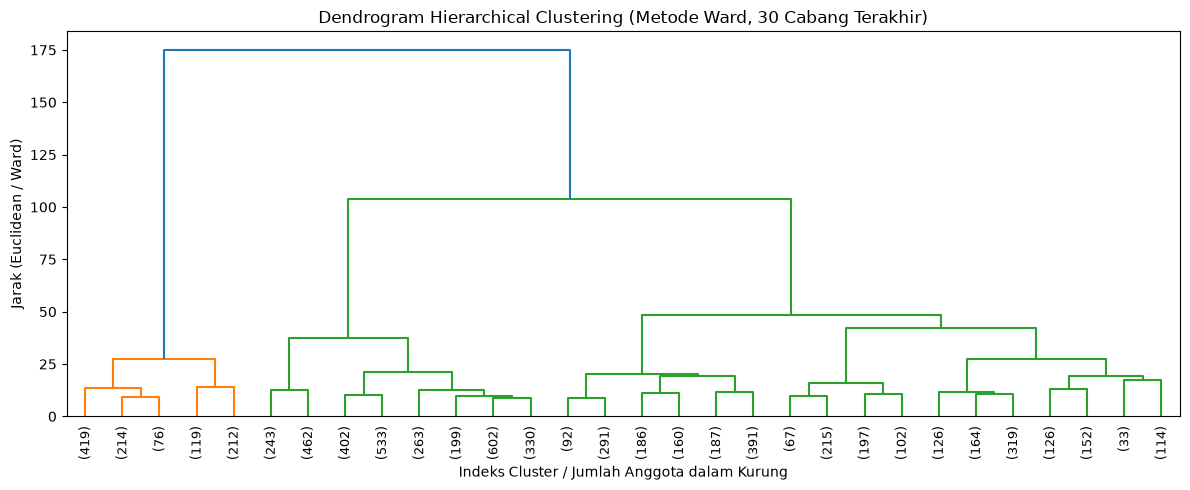

In [21]:
# Tampilkan dendrogram dari linkage matrix di atas.
# Batasi tampilan agar mudah dibaca (misalnya truncate_mode='lastp' atau p=30).
# Amati pada ketinggian berapa sebaiknya dendrogram dipotong untuk menentukan jumlah cluster.
plt.figure(figsize=(12, 5))
dendrogram(
    linkage_matrix,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90,
    leaf_font_size=9
)
plt.title('Dendrogram Hierarchical Clustering (Metode Ward, 30 Cabang Terakhir)')
plt.xlabel('Indeks Cluster / Jumlah Anggota dalam Kurung')
plt.ylabel('Jarak (Euclidean / Ward)')
plt.tight_layout()
plt.show()

## 4.2 Perbandingan Metode Linkage

Linkage menentukan cara jarak antar cluster dihitung. Pada bagian ini kalian akan membandingkan empat metode linkage: ward, complete, average, dan single.

### Penjelasan Langkah 4.2.1: Melatih 4 Variasi Linkage (ward, complete, average, single)
Konsep: Keempat metode memiliki aturan berbeda dalam mengukur jarak antar dua kelompok:
1. ward: Meminimalkan kenaikan varians di dalam cluster.
2. complete: Mengukur jarak dari dua titik yang paling jauh antar kelompok.
3. average: Mengukur rata-rata jarak semua pasangan titik antar kelompok.
4. single: Mengukur jarak dari dua titik yang paling dekat antar kelompok.

Apa saja yang dilakukan: Melatih AgglomerativeClustering(n_clusters=3) untuk keempat metode linkage tersebut pada X_log_scaled dan menyimpan label hasilnya ke dictionary hc_results.

Tujuannya: Menguji empat aturan penggabungan kelompok (ward, complete, average, single) untuk melihat pengaruh masing-masing terhadap bentuk cluster.

In [22]:
# Latih AgglomerativeClustering dengan masing-masing linkage (ward, complete, average, single).
# Gunakan jumlah cluster yang sama untuk semua linkage agar perbandingan adil.
linkage_methods = ['ward', 'complete', 'average', 'single']
hc_results = {}

for method in linkage_methods:
    hc = AgglomerativeClustering(n_clusters=k_optimal, linkage=method)
    hc_results[method] = hc.fit_predict(X_log_scaled)

print("Keempat model AgglomerativeClustering selesai dilatih.")

Keempat model AgglomerativeClustering selesai dilatih.


### Penjelasan Langkah 4.2.2: Membandingkan Silhouette Score dan Keseimbangan Anggota
Konsep: Metode linkage yang baik tidak hanya punya Silhouette Score bagus, tetapi juga harus menghasilkan ukuran cluster yang masuk akal. Pada metode single linkage sering terjadi efek berantai (*chaining effect*), di mana hampir seluruh data masuk ke 1 cluster raksasa dan cluster lainnya hanya berisi 1 atau 2 data pencilan (*outlier*).

Apa saja yang dilakukan: Menghitung Silhouette Score dan jumlah anggota tiap cluster untuk keempat metode linkage, lalu menyajikannya dalam satu tabel perbandingan.

Tujuannya: Menilai linkage mana yang menghasilkan kelompok seimbang dan mendeteksi linkage mana yang gagal karena menumpuk data di satu cluster.

In [23]:
# Hitung Silhouette Score untuk setiap linkage dan tampilkan jumlah anggota tiap cluster.
# Sajikan dalam satu tabel perbandingan.
# Amati apakah ada linkage yang menghasilkan cluster sangat tidak seimbang (misalnya satu cluster sangat besar dan lainnya hanya beberapa titik).
tabel_linkage = []
for method, labels in hc_results.items():
    sil = silhouette_score(X_log_scaled, labels)
    counts = pd.Series(labels).value_counts().sort_index().to_dict()
    tabel_linkage.append({
        'Linkage': method,
        'Silhouette Score': round(sil, 4),
        'Jumlah Anggota per Cluster': counts
    })

df_linkage = pd.DataFrame(tabel_linkage)
df_linkage

,Linkage,Silhouette Score,Jumlah Anggota per Cluster
0,ward,0.4201,"{0: 2922, 1: 1040, 2: 3034}"
1,complete,0.1163,"{0: 5775, 1: 460, 2: 761}"
2,average,0.5069,"{0: 1197, 1: 5764, 2: 35}"
3,single,0.3139,"{0: 6994, 1: 1, 2: 1}"


Pilihan linkage untuk Hierarchical Clustering:
Dipilih metode ward. Meskipun average memiliki Silhouette Score sedikit lebih tinggi (0.5069), pembagian anggotanya sangat timpang karena satu cluster berisi 5.764 data sementara cluster lain hanya 35 data. Metode single bahkan lebih ekstrem lagi karena hampir seluruh data menumpuk di satu cluster (6.994 data) dan dua cluster lain masing-masing hanya berisi 1 data. Sebaliknya, ward menghasilkan Silhouette Score yang baik (0.4201) dengan jumlah anggota tiap cluster yang sangat seimbang (2.922, 1.040, dan 3.034 posting).

## 4.3 Model Hierarchical Clustering Final

### Penjelasan Langkah 4.3.1: Melatih Model Hierarchical Clustering Final
Konsep: Kita memilih metode linkage terbaik dari tabel perbandingan sebelumnya (umumnya ward karena seimbang dan terstruktur) dengan jumlah cluster yang sama dengan K-Means.

Apa saja yang dilakukan: Melatih AgglomerativeClustering final dengan n_clusters=3 dan linkage='ward' pada X_log_scaled, lalu menyimpan labelnya ke labels_hc.

Tujuannya: Membangun model Hierarchical Clustering final menggunakan metode terbaik agar siap dibandingkan secara adil dengan K-Means.

In [24]:
# Latih model AgglomerativeClustering final dengan linkage terbaik dan jumlah cluster yang sama dengan K-Means final.
# Simpan label cluster hasil prediksi untuk keperluan evaluasi.
hc_final = AgglomerativeClustering(n_clusters=k_optimal, linkage='ward')
labels_hc = hc_final.fit_predict(X_log_scaled)

print("Jumlah anggota tiap cluster (Hierarchical Ward):")
print(pd.Series(labels_hc).value_counts().sort_index())

Jumlah anggota tiap cluster (Hierarchical Ward):
0    2922
1    1040
2    3034
Name: count, dtype: int64


### Penjelasan Langkah 4.3.2: Profil Cluster Hierarchical Clustering pada Data Asli
Konsep: Sama seperti pada K-Means, kita menghitung median dan rata-rata setiap fitur pada data asli (X_raw_df) berdasarkan label cluster hasil Hierarchical Clustering.

Apa saja yang dilakukan: Menggabungkan labels_hc dengan X_raw_df, lalu menampilkan jumlah anggota, nilai median, dan rata-rata setiap fitur per cluster.

Tujuannya: Mengetahui ciri khas median dan rata-rata engagement tiap cluster Hierarchical Clustering untuk dicocokkan dengan profil K-Means.

In [25]:
# Buat profil setiap cluster pada data ASLI (sebelum transformasi log dan scaling): tampilkan median (dan rata-rata) tiap fitur per cluster beserta jumlah anggotanya.
profil_hc = X_raw_df.copy()
profil_hc['Cluster'] = labels_hc

ringkas_hc = profil_hc.groupby('Cluster')[selected_features].median()
ringkas_hc.insert(0, 'Jumlah Anggota', profil_hc['Cluster'].value_counts().sort_index())
print("=== Jumlah Anggota & Median Tiap Fitur per Cluster (Hierarchical) ===")
print(ringkas_hc)

print("\n=== Rata-Rata (Mean) Tiap Fitur per Cluster (Hierarchical) ===")
print(profil_hc.groupby('Cluster')[selected_features].mean().round(2))

=== Jumlah Anggota & Median Tiap Fitur per Cluster (Hierarchical) ===
         Jumlah Anggota  num_likes  num_comments  num_shares  num_emojis
Cluster                                                                 
0                  2922      150.0           9.0         1.0         1.0
1                  1040      168.0         815.5       193.5        60.5
2                  3034       14.0           0.0         0.0         0.0

=== Rata-Rata (Mean) Tiap Fitur per Cluster (Hierarchical) ===
         num_likes  num_comments  num_shares  num_emojis
Cluster                                                 
0           386.75         29.40        5.27        4.48
1           277.53       1430.19      255.40       88.24
2            16.71          1.76        0.25        0.15


# 5. Evaluasi Model

### Penjelasan Langkah 5.1: Perbandingan Metrik Evaluasi Internal
Konsep: Karena clustering tidak punya kunci jawaban asli, kualitasnya diukur dengan metrik evaluasi internal berdasarkan bentuk dan jarak titik data:
1. Silhouette Score: Semakin tinggi (mendekati 1) semakin baik, artinya tiap cluster rapat dan terpisah jelas.
2. Davies-Bouldin Index (DBI): Semakin rendah (mendekati 0) semakin baik, artinya kemiripan antar cluster yang berbeda sangat kecil.
3. Calinski-Harabasz Score: Semakin tinggi semakin baik, mengukur perbandingan kepadatan dalam cluster dibanding jarak antar cluster.

Apa saja yang dilakukan: Menghitung ketiga metrik evaluasi internal (silhouette_score, davies_bouldin_score, calinski_harabasz_score) untuk K-Means dan Hierarchical (Ward), lalu menampilkannya dalam satu tabel perbandingan.

Tujuannya: Membandingkan kualitas akhir K-Means dan Hierarchical Clustering secara adil menggunakan tiga metrik evaluasi matematis sekaligus.

In [26]:
# Hitung metrik evaluasi INTERNAL untuk K-Means dan Hierarchical Clustering:
# Silhouette Score (semakin tinggi semakin baik), Davies-Bouldin Index (semakin rendah semakin baik), dan Calinski-Harabasz Score (semakin tinggi semakin baik).
# Sajikan dalam satu tabel perbandingan.
eval_list = []
for nama, lbl in [('K-Means', labels_kmeans), ('Hierarchical (Ward)', labels_hc)]:
    eval_list.append({
        'Model': nama,
        'Silhouette Score (Tinggi=Baik)': round(silhouette_score(X_log_scaled, lbl), 4),
        'Davies-Bouldin Index (Rendah=Baik)': round(davies_bouldin_score(X_log_scaled, lbl), 4),
        'Calinski-Harabasz Score (Tinggi=Baik)': round(calinski_harabasz_score(X_log_scaled, lbl), 2)
    })

df_eval = pd.DataFrame(eval_list)
df_eval

,Model,Silhouette Score (Tinggi=Baik),Davies-Bouldin Index (Rendah=Baik),Calinski-Harabasz Score (Tinggi=Baik)
0,K-Means,0.4638,0.8302,10935.46
1,Hierarchical (Ward),0.4201,0.8329,9959.19


### Penjelasan Langkah 5.2: Visualisasi Cluster dengan PCA 2 Dimensi
Konsep: Data kita memiliki 4 fitur (4 dimensi), padahal layar monitor hanya bisa menggambar grafik 2 dimensi (sumbu X dan sumbu Y). PCA (Principal Component Analysis) memeras 4 fitur tersebut menjadi 2 komponen utama (PC1 dan PC2) dengan mempertahankan informasi (varians) sebanyak mungkin.

Apa saja yang dilakukan: Menerapkan PCA(n_components=2) pada X_log_scaled, mencetak persentase varians yang dijelaskan PC1 dan PC2, lalu menggambar scatter plot cluster K-Means dan Hierarchical berdampingan.

Tujuannya: Memproyeksikan data 4 dimensi ke grafik 2 dimensi agar kita bisa melihat dengan mata sendiri kemiripan atau perbedaan posisi cluster kedua metode.

Varians yang dijelaskan oleh PC1: 75.87%, PC2: 15.95% (Total: 91.82%)


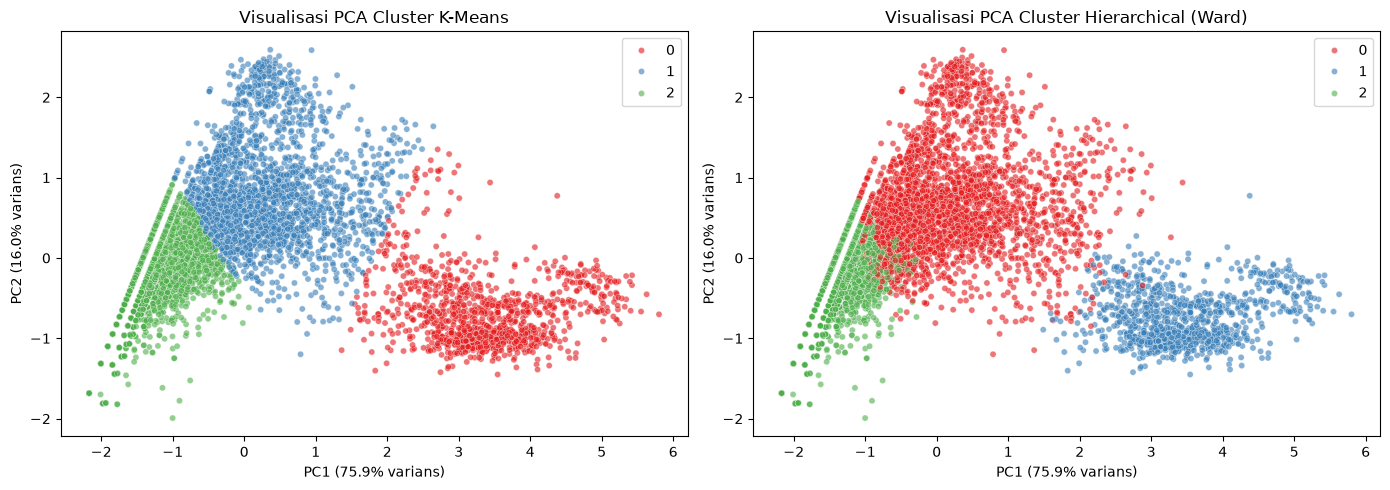

In [27]:
# Lakukan PCA ke 2 komponen pada X_log_scaled.
# Tampilkan scatter plot hasil clustering K-Means dan Hierarchical Clustering dalam satu baris subplot, diwarnai berdasarkan label cluster.
# Tampilkan juga persentase varians yang dijelaskan oleh kedua komponen PCA.
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_log_scaled)
var_ratio = pca.explained_variance_ratio_ * 100

print(f"Varians yang dijelaskan oleh PC1: {var_ratio[0]:.2f}%, PC2: {var_ratio[1]:.2f}% (Total: {var_ratio.sum():.2f}%)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot K-Means
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=labels_kmeans, palette='Set1', alpha=0.6, s=20, ax=axes[0])
axes[0].set_title('Visualisasi PCA Cluster K-Means')
axes[0].set_xlabel(f'PC1 ({var_ratio[0]:.1f}% varians)')
axes[0].set_ylabel(f'PC2 ({var_ratio[1]:.1f}% varians)')

# Plot Hierarchical
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=labels_hc, palette='Set1', alpha=0.6, s=20, ax=axes[1])
axes[1].set_title('Visualisasi PCA Cluster Hierarchical (Ward)')
axes[1].set_xlabel(f'PC1 ({var_ratio[0]:.1f}% varians)')
axes[1].set_ylabel(f'PC2 ({var_ratio[1]:.1f}% varians)')

plt.tight_layout()
plt.show()

### Penjelasan Langkah 5.3: Interpretasi Cluster dengan Komposisi status_type
Konsep: Di tahap evaluasi akhir ini, barulah kita membuka kembali kolom status_type (video, photo, status, link) dan menghitung tabel silang (*crosstab*) dalam satuan persen untuk melihat tipe posting apa yang paling banyak mengisi tiap cluster.

Apa saja yang dilakukan: Membuat tabel crosstab dalam persentase antara label cluster dengan status_type untuk K-Means dan Hierarchical, lalu memvisualisasikannya dalam dua heatmap berdampingan.

Tujuannya: Mengetahui jenis posting apa (video, photo, status, link) yang mendominasi tiap cluster sehingga kita bisa memberi julukan bisnis yang tepat.

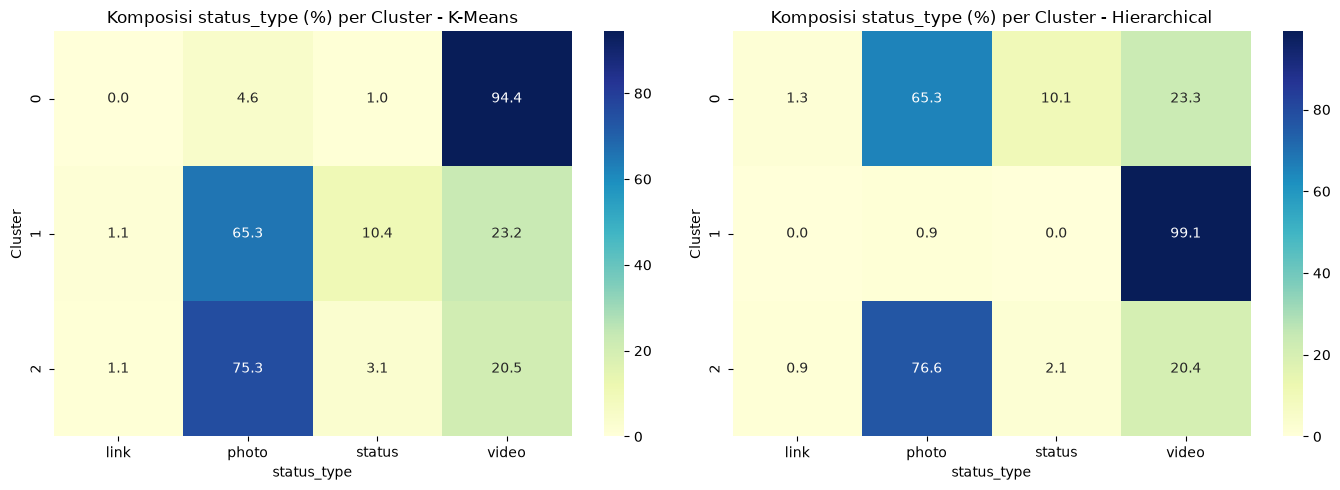

In [28]:
# Tampilkan komposisi status_type pada tiap cluster (crosstab dalam persen) untuk K-Means dan Hierarchical Clustering dalam bentuk heatmap.
# Susun keduanya dalam satu baris subplot.
# Ini hanya untuk membantu interpretasi cluster, bukan sebagai label asli.
ct_km = pd.crosstab(labels_kmeans, meta_df['status_type'], normalize='index') * 100
ct_hc = pd.crosstab(labels_hc, meta_df['status_type'], normalize='index') * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(ct_km, annot=True, fmt='.1f', cmap='YlGnBu', ax=axes[0])
axes[0].set_title('Komposisi status_type (%) per Cluster - K-Means')
axes[0].set_xlabel('status_type')
axes[0].set_ylabel('Cluster')

sns.heatmap(ct_hc, annot=True, fmt='.1f', cmap='YlGnBu', ax=axes[1])
axes[1].set_title('Komposisi status_type (%) per Cluster - Hierarchical')
axes[1].set_xlabel('status_type')
axes[1].set_ylabel('Cluster')

plt.tight_layout()
plt.show()

# 6. Analisis

### 1. Pengaruh Transformasi Log dan Feature Scaling pada K-Means
1. Pada data mentah tanpa olahan (X_raw), rentang angka antar fitur sangat jomplang. Kolom num_comments punya penyebaran angka (varians) sebesar 797.310 dan num_likes sebesar 193.268, sedangkan num_emojis hanya 2.299. Karena K-Means mengukur kedekatan data lewat jarak angka, kolom yang angkanya ribuan otomatis menguasai perhitungan. Akibatnya, Cluster 0 menampung hampir semua data (6.392 posting) dan skor kerapian kelompoknya (Silhouette Score) rendah, yaitu 0.2731.
2. Jika kita hanya menyamakan skala tanpa transformasi log (X_raw_scaled), masalahnya belum selesai karena sebaran datanya sangat miring (banyak posting bernilai kecil, tapi ada segelintir posting viral bernilai puluhan ribu). Nilai raksasa (outlier) tersebut tetap menarik titik pusat cluster terlalu jauh, sehingga Cluster 1 masih menumpuk 6.277 data dan Silhouette Score hanya 0.2533.
3. Setelah menggabungkan transformasi log1p (untuk merapatkan angka raksasa agar tidak terlalu jauh dari angka biasa) dan StandardScaler (untuk menyamakan skala semua kolom), hasilnya berubah drastis. Silhouette Score melonjak menjadi 0.4638 dan jumlah anggota tiap cluster terbagi jauh lebih merata (1.131, 2.258, dan 3.607 posting).

### 2. Penanganan Fitur Redundan dan Fitur Banyak Bernilai Nol
1. Empat kolom kosong (Column1 sampai Column4) dibuang karena tidak berisi informasi apa pun, dan 54 baris kembar (ketika status_id diabaikan) dihapus supaya data ganda tidak menarik titik pusat cluster.
2. Kolom num_reactions dibuang karena terbukti kembar atau redundan: pada 7.041 dari 7.050 baris, nilainya sama persis dengan hasil penjumlahan num_likes ditambah semua reaksi emoji. Jika tetap dimasukkan, informasi yang sama akan dihitung dua kali oleh algoritma.
3. Lima kolom reaksi emoji (num_loves, num_wows, num_hahas, num_sads, num_angrys) berisi 60 persen hingga 94 persen angka nol karena tombol emoji baru muncul di Facebook sejak tahun 2016. Kelimanya digabung menjadi satu kolom num_emojis agar informasi reaksi emosional tetap terpakai tanpa membuat model dipenuhi kolom yang hampir kosong.

### 3. Penentuan Jumlah Cluster Optimal (Elbow vs Silhouette)
1. Elbow Method: Pada grafik Elbow, penurunan nilai error jarak dalam cluster (inertia) paling tajam terjadi saat berpindah dari k = 2 (11.586,90) ke k = 3 (6.779,84). Setelah k = 3, penurunannya mulai melambat (k = 4 menjadi 5.678,25). Jadi bentuk siku pada grafik terlihat jelas di k = 3.
2. Silhouette Score: Skor tertinggi memang ada di k = 2 (0.5899), tetapi pada k = 3 nilainya masih tergolong baik (0.4638) sebelum akhirnya turun tajam ke 0.3372 pada k = 4.
3. Keputusan: Meskipun puncak angka keduanya berbeda (2 vs 3), dipilih k = 3 karena menjadi titik tengah terbaik. Selain didukung bentuk siku di Elbow Method dan skor Silhouette yang masih kuat, membagi posting menjadi 3 kelompok (sepi, populer biasa, dan live video ramai) jauh lebih berguna secara bisnis dibanding hanya 2 kelompok.

### 4. Perbandingan Metode Linkage pada Hierarchical Clustering
1. ward adalah metode terbaik: menghasilkan Silhouette Score 0.4201 dengan ukuran tiga kelompok yang paling seimbang (2.922, 1.040, dan 3.034 posting).
2. single mengalami efek rantai (chaining effect): hampir semua data (6.994 posting) menyambung menjadi satu cluster raksasa, sementara dua cluster lainnya masing-masing hanya berisi 1 posting saja. Metode ini gagal membagi kelompok dengan baik.
3. average mendapat Silhouette Score 0.5069, tetapi pembagiannya sangat berat sebelah (5.764 vs 1.197 vs 35 data) karena mudah terpengaruh oleh kelompok kecil data yang angkanya ekstrem.
4. complete memperoleh Silhouette Score paling rendah (0.1163) dengan pembagian kelompok yang juga timpang (5.775 vs 460 vs 761 data).

### 5. Perbandingan Performa K-Means vs Hierarchical Clustering
1. Metrik Evaluasi Internal: K-Means sedikit lebih unggul di ketiga ukuran kualitas cluster: Silhouette Score lebih tinggi (0.4638 vs 0.4201, artinya kelompok lebih rapat dan terpisah rapi), Davies-Bouldin Index lebih rendah (0.8302 vs 0.8329, artinya kemiripan antar kelompok berbeda lebih kecil), dan Calinski-Harabasz Score lebih tinggi (10.935,46 vs 9.959,19).
2. Visualisasi PCA 2D: Dua sumbu grafik PCA berhasil merangkum 91,82 persen total informasi dari 4 fitur asli (PC1 = 75,87 persen dan PC2 = 15,95 persen), sehingga gambar 2D-nya sangat mewakili kondisi data asli. Pada grafik terlihat batas dan letak ketiga cluster milik K-Means dan Hierarchical (Ward) sangat mirip karena kedua metode sama-sama bertujuan mengelompokkan titik yang berdekatan.

### 6. Karakteristik dan Julukan Tiap Cluster
Berdasarkan nilai tengah (median) data asli dan jenis posting (status_type) di tiap kelompok:
1. Cluster 0 K-Means (1.131 data) / Cluster 1 Hierarchical (1.040 data) -> Julukan: "Live Video Interaktif / Ramai Pembeli".
   Ciri khasnya memiliki jumlah komentar sangat tinggi (median 722 di K-Means dan 815,5 di Hierarchical), jumlah share tinggi (178 / 193,5), serta emoji tinggi (57 / 60,5). Hampir seluruh isinya adalah Video (94,4 persen di K-Means dan 99,1 persen di Hierarchical). Ini adalah siaran langsung jualan di mana pembeli aktif bertanya di komentar dan membagikan video.
2. Cluster 1 K-Means (2.258 data) / Cluster 0 Hierarchical (2.922 data) -> Julukan: "Katalog Populer (Banyak Like)".
   Ciri khasnya memiliki jumlah like paling tinggi (median 206 di K-Means dan 150 di Hierarchical), tetapi komentarnya sedikit (9 sampai 11) dan hampir tidak ada share (median 1). Sebagian besar isinya adalah Photo (65,3 persen) dan sedikit Video (sekitar 23 persen). Ini menggambarkan posting foto produk menarik yang disukai audiens, namun jarang memicu obrolan panjang.
3. Cluster 2 K-Means (3.607 data) / Cluster 2 Hierarchical (3.034 data) -> Julukan: "Posting Pasif / Sepi Interaksi".
   Ciri khasnya paling rendah di semua angka: median like hanya 14 sampai 18, sedangkan komentar, share, dan emoji semuanya bernilai tengah 0. Didominasi Photo (75,3 persen sampai 76,6 persen). Ini adalah posting rutin yang kurang mendapat perhatian pembeli.

### 7. Kelebihan dan Kekurangan Masing-Masing Metode
1. K-Means: Sangat cepat dan hemat memori komputer karena hanya menghitung jarak data ke beberapa titik pusat cluster. Kekurangannya, kita harus menebak jumlah cluster (k) sejak awal dan bentuk kelompoknya cenderung bulat-bulat saja.
2. Hierarchical Clustering (Agglomerative): Kelebihannya kita tidak perlu menebak jumlah cluster di awal karena bisa melihat struktur pohon penggabungannya dulu lewat dendrogram. Kekurangannya, metode ini butuh memori dan waktu jauh lebih besar karena harus menghitung jarak antar semua pasangan baris satu per satu, sehingga akan terasa lambat jika datanya puluhan atau ratusan ribu baris.

# 7. Kesimpulan dan Saran

### Kesimpulan
1. Preprocessing berupa pembuangan fitur redundan (num_reactions), penggabungan fitur sparse (num_emojis), transformasi log1p, dan scaling StandardScaler merupakan kunci utama keberhasilan clustering pada data media sosial yang miring. Silhouette Score K-Means meningkat dari 0.2731 (data mentah) menjadi 0.4638 (X_log_scaled).
2. Jumlah cluster optimal adalah k = 3, yang berhasil memisahkan posting penjual menjadi tiga segmen nyata: Posting Pasif (sepi interaksi), Katalog Populer (banyak like), dan Live Video Interaktif (sangat ramai komentar dan share).
3. Pada Hierarchical Clustering, metode ward memberikan hasil terbaik dan paling seimbang, sedangkan single gagal karena mengalami *chaining effect*.
4. Secara keseluruhan, K-Means memberikan performa metrik internal sedikit lebih baik dibanding Hierarchical Clustering (Ward) sekaligus jauh lebih ringan secara komputasi, meskipun pola kelompok yang ditemukan oleh keduanya sangat konsisten (sejalan dengan komposisi status_type).

### Saran
1. Analisis Terpisah Sebelum dan Sesudah 2016: Karena fitur reaksi emoji baru muncul di tahun 2016, memisahkan clustering untuk data 2012 sampai 2015 dan 2016 sampai 2018 dapat menghindari bias nilai 0 emoji pada posting lama.
2. Menambahkan Fitur Waktu Posting: Memanfaatkan kolom status_published (seperti jam posting atau hari kerja vs akhir pekan) untuk melihat apakah jam live streaming memengaruhi masuknya posting ke cluster ramai.
3. Mencoba Algoritma Berbasis Kepadatan atau Probabilitas: Eksperimen lanjutan bisa mencoba DBSCAN untuk memisahkan posting super viral sebagai outlier secara otomatis, atau Gaussian Mixture Model (GMM) untuk bentuk cluster yang lebih fleksibel.
4. Tuning Parameter K-Means: Mencoba nilai n_init yang lebih besar atau membandingkan inisialisasi k-means++ vs random untuk memastikan hasil centroid selalu stabil.